<a href="https://colab.research.google.com/github/duyuanjun673-rgb/Yuanjun-Du/blob/main/student_demo/Yuanjun_Du/week03_03_Yuanjun_Du.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# STATS 201 Week 3 · 03 Supervised Prediction

**Question.** Can a classifier label completion for a frame from an unseen robot trajectory?

**How to work.** In Colab, choose **File → Save a copy in Drive**. Run the cells in order on CPU. Read the saved default outputs if Hugging Face is temporarily unavailable. Use VIEW = "all" and THRESHOLD = 0.50 first. Then try the wrist camera and inspect the error again.

For Ed, share one figure or panel, a view-access link to your Colab copy, your interpretation and one check. The result displays inline.

## 1 · Define the target and the holdout

The task is to classify whether the action is complete in a previously unseen frame. We use labeled examples from other robot runs and reserve the entire trajectory 14652 for the check. Decide what visual cues could help a classifier identify completion.

### Prediction pseudocode and intuition

This lab learns from robot frames with recorded answers and then scores frames from a different run. An image becomes a row of pixel features. Logistic regression combines those features into a single number and converts it to a score between 0 and 1 for the **Yes** class.

```text
Read the 600 source rows and find the two target frames
Set aside the entire target trajectory 14652
From the other trajectories, keep completion questions with Yes or No references
FOR each training and test image
    Choose the full montage or the wrist crop
    Resize to 24 by 14 pixels, flatten RGB channels and scale by 255
END FOR
Fit class-weighted logistic regression to the training pixels and labels
FOR each test frame i
    Compute its Yes score p[i]
    IF p[i] is at least THRESHOLD, predict Yes
    OTHERWISE, predict No
    Compare the resulting label with the decoded reference and the always-No baseline
END FOR
Repeat the fit for the other camera view to draw the comparison gallery
```

The fitted model combines the pixels $x_i$ as $b+w^\top x_i$ and converts that value to the Yes score $p_i=1/(1+\exp(-(b+w^\top x_i)))$. The predicted answer $\widehat y_i$ depends on the cutoff $t$, and the observed reference $y_i$ comes from the row's own answer choices. [Logistic regression documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)

In [25]:
# Read and run. The data loader makes public Hugging Face requests.

import json
import time
from io import BytesIO
from urllib.error import HTTPError, URLError
from urllib.parse import urlencode
from urllib.request import urlopen

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image as NotebookImage, display

import ast
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
from PIL import Image
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits

DATA_SERVER = "https://datasets-server.huggingface.co"
ROBOT = "keplerccc/Robo2VLM-1"
TARGET_IDS = ("14652_q29", "14652_q35")

def read_url(url):
    for attempt in range(5):
        try:
            with urlopen(url, timeout=25) as response:
                return response.read()
        except (URLError, TimeoutError) as error:
            if isinstance(error, HTTPError) and error.code not in {429, 500, 502, 503, 504}:
                raise RuntimeError(f"Hugging Face returned HTTP {error.code}. Rerun the data cell.") from error
            if attempt == 4:
                raise RuntimeError("Hugging Face is unavailable. The saved default outputs can support discussion.") from error
            time.sleep(2 ** attempt)

def page(dataset, offset=0, first=False):
    params = {"dataset": dataset, "config": "default", "split": "train"}
    endpoint = "first-rows" if first else "rows"
    if not first:
        params.update(offset=offset, length=100)
    return json.loads(read_url(f"{DATA_SERVER}/{endpoint}?{urlencode(params)}"))["rows"]

def show_figure(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=125, bbox_inches="tight")
    plt.close(fig)
    display(NotebookImage(data=buffer.getvalue()))

In [26]:
# Read and run. Each row has its own choice order.
def reference_answer(row):
    choices = row["choices"]
    choices = ast.literal_eval(choices) if isinstance(choices, str) else choices
    return choices[row["correct_answer"]]

first_robot = [entry["row"] for entry in page(ROBOT, first=True)]
targets = [next(row for row in first_robot if row["id"].endswith(key)) for key in TARGET_IDS]

# Read and run once. Download only the filtered training images and the two test images.
def load_robot_page(offset):
    return first_robot if offset == 0 else [item["row"] for item in page(ROBOT, offset)]

def trajectory(row):
    return row["id"].rsplit("_q", 1)[0]

def image_from_row(row):
    with Image.open(BytesIO(read_url(row["image"]["src"]))) as img:
        return img.convert("RGB")

with ThreadPoolExecutor(max_workers=2) as pool:
    rows = [row for batch in pool.map(load_robot_page, range(0, 600, 100)) for row in batch]
held_out = trajectory(targets[0])
assert all(trajectory(row) == held_out for row in targets)

training = [row for row in rows
            if trajectory(row) != held_out
            and row["question"].endswith("Has the robot successfully completed the task?")
            and reference_answer(row) in {"Yes", "No"}]
training_labels = [reference_answer(row) for row in training]
with ThreadPoolExecutor(max_workers=4) as pool:
    train_images = list(pool.map(image_from_row, training))
    test_images = list(pool.map(image_from_row, targets))

print(f"Rows read: {len(rows)}")
print(f"Training: {len(training)} labelled images from {len({trajectory(row) for row in training})} other trajectories")
print(f"Training labels: {dict(sorted(Counter(training_labels).items()))}")
print(f"Held-out trajectory: {held_out.rsplit('_', 1)[-1]}")

Rows read: 600
Training: 94 labelled images from 16 other trajectories
Training labels: {'No': 79, 'Yes': 15}
Held-out trajectory: 14652


### Read the sample and the holdout

| Printed quantity | Meaning |
|---|---|
| 600 source rows | Image–question records fetched for the teaching slice. The selection step keeps the relevant completion questions. |
| 94 training images across 16 trajectories | The input used to fit the classifier. Several records can come from the same robot run. |
| 79 No and 15 Yes | The training label counts. Yes accounts for about **16.0%** of the training rows, so the majority baseline always predicts No. |
| Held-out trajectory 14652 | The run set aside from training. The two displayed test frames both come from this run. |

Resizing each image gives $24\times14\times3=1{,}008$ features. A training weight of $n/(2n_c)$ for a class with $n_c$ rows gives the rarer Yes class about 3.13 per row and the No class about 0.59 per row. These weights give each class the same total weight in fitting. [Class-weight definition](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)

## 2 · Fit and compare

**Your turn.** Start with **VIEW = "all"**, then try **"wrist"**. Keep **THRESHOLD = 0.50** for the camera comparison. Then use the score table to explore a different decision threshold.

Pillow crops and resizes the camera images. NumPy stacks RGB features. scikit-learn fits logistic regression. pandas displays the predictions, reference labels and majority baseline.

In [30]:
# Your turn · change one setting after the default run.
VIEW = "wrist"  # "all" or "wrist"
THRESHOLD = 0.50  # a number strictly between 0 and 1
assert 0 < THRESHOLD < 1

def camera_view(img, view):
    if view == "all":
        return img
    if view == "wrist":
        width, height = img.size
        return img.crop((0, height // 2, width // 2, height))
    raise ValueError('Choose VIEW = "all" or VIEW = "wrist".')

def pixels(img, view):
    thumbnail = camera_view(img, view).resize((24, 14), Image.Resampling.BILINEAR)
    return np.asarray(thumbnail, dtype=np.float32).ravel() / 255

def fit_camera(view):
    x_train = np.stack([pixels(img, view) for img in train_images])
    x_test = np.stack([pixels(img, view) for img in test_images])
    labels = np.array([answer == "Yes" for answer in training_labels], dtype=int)
    classifier = LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000, random_state=0)
    with threadpool_limits(limits=1):
        classifier.fit(x_train, labels)
    yes_scores = classifier.predict_proba(x_test)[:, list(classifier.classes_).index(1)]
    return x_train, x_test, labels, classifier, yes_scores

X_train, X_test, y_train, model, scores = fit_camera(VIEW)
predictions = np.where(scores >= THRESHOLD, "Yes", "No")

In [31]:
# Read and run. Compare the chosen view with the baseline and the reference.
references = [reference_answer(row) for row in targets]
result = pd.DataFrame({
    "Frame": TARGET_IDS,
    "Yes score": np.round(scores, 3),
    "Prediction": predictions,
    "Reference": references,
    "Baseline": ["No"] * len(TARGET_IDS),
})
result["Matches reference"] = result["Prediction"] == result["Reference"]
display(result)

,Frame,Yes score,Prediction,Reference,Baseline,Matches reference
0,14652_q29,0.037,No,No,No,True
1,14652_q35,0.350,No,Yes,No,False


### Read the scores, cutoff and reference

**Compare the Yes score for each frame with the decision threshold.** With all cameras and the default cutoff of 0.50, $0.040$ for q29 and $0.086$ for q35 both fall below the cutoff. Both decisions are No. The **Reference** column is the observed label recorded by the dataset. The **Matches reference** column checks whether that label agrees with the model's decision.

The result is a correct No for q29 and a **false negative** for q35, whose reference says Yes. The logistic classifier and the always-No baseline each match **1 of 2** references. Each catches **0 of 1** observed Yes cases. These fractions describe the two displayed frames.

**Try the cutoff rule by hand.** A threshold of 0.21 also puts both all-view scores below the cutoff. At 0.05, q35 reaches the cutoff and switches to Yes. q29 falls below 0.05. This comparison applies different decision rules to the displayed scores.

## 3 · Prediction gallery

Rerun the fit, prediction table and gallery after changing a setting. Which error persists when you change the view? Who could be affected? The gallery displays inline and can also be saved as a PNG.

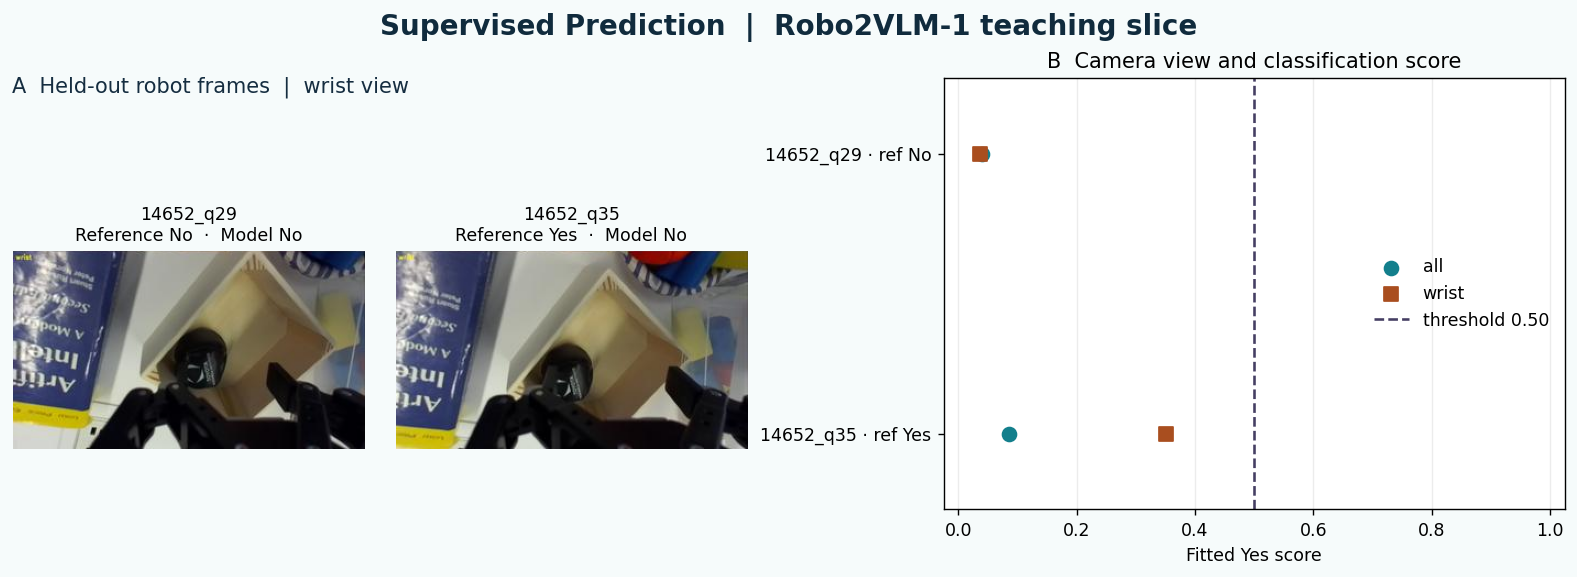

In [32]:
# Read and run after fitting. This cell makes the two-panel gallery.
def prediction_gallery(filename="STATS201_Week3_Prediction_Gallery.png"):
    alternative = "wrist" if VIEW == "all" else "all"
    by_view = {VIEW: scores, alternative: fit_camera(alternative)[-1]}
    fig = plt.figure(figsize=(12.5, 4.5), layout="constrained", facecolor="#f6fbfb")
    panels = fig.add_gridspec(1, 2, width_ratios=[1.2, 1])
    images = panels[0].subgridspec(2, 2, height_ratios=[.17, 1])
    label = fig.add_subplot(images[0, :])
    label.set_axis_off()
    label.text(0, .45, f"A  Held-out robot frames  |  {VIEW} view",
               fontsize=12, color="#152d40", fontweight="medium")
    axes = [fig.add_subplot(images[1, 0]), fig.add_subplot(images[1, 1])]
    for ax, img, frame, ref, predicted in zip(axes, test_images, TARGET_IDS, references, predictions):
        ax.imshow(camera_view(img, VIEW))
        ax.set_title(f"{frame}\nReference {ref}  ·  Model {predicted}", fontsize=10)
        ax.set_axis_off()

    b = fig.add_subplot(panels[1])
    for view, marker, color in (("all", "o", "#137f8c"), ("wrist", "s", "#a94e1f")):
        b.scatter(by_view[view], [0, 1], marker=marker, color=color, s=64, label=view, zorder=3)
    b.axvline(THRESHOLD, color="#453e63", linestyle="--", label=f"threshold {THRESHOLD:.2f}")
    b.set(xlim=(-.025, 1.025), ylim=(1.27,-.27), yticks=[0,1],
          yticklabels=[f"{frame} · ref {ref}" for frame, ref in zip(TARGET_IDS,references)],
          title="B  Camera view and classification score", xlabel="Fitted Yes score")
    b.grid(axis="x", alpha=.23)
    b.legend(frameon=False, loc="center right")
    fig.suptitle("Supervised Prediction  |  Robo2VLM-1 teaching slice",
                 fontsize=16, color="#102b3d", fontweight="bold")
    if filename:
        fig.savefig(filename, dpi=150, facecolor=fig.get_facecolor(), bbox_inches="tight")
    show_figure(fig)
    return by_view

view_scores = prediction_gallery()

### Read the images and score comparison

| Frame | All-views Yes score | Wrist-view Yes score | Recorded reference |
|---|---:|---:|---|
| q29 | 0.040 | 0.037 | No |
| q35 | 0.086 | 0.350 | Yes |

**Panel A** shows the selected view and places the predicted and reference labels above each image. **Panel B** compares two fitted models on the same frames. Its horizontal axis is the Yes score. The row identifies the frame. Circles show all-view scores, squares show wrist-view scores, and the dashed line marks the current cutoff. At 0.50, the q35 points for both views lie to the left of the line. The wrist crop brings its score closer to the cutoff.

## Conclusions and assumptions

**What the results support.** In this run, the camera view affects the Yes score for q35, and the default decision misses its recorded completion. The always-No baseline matches the model on these two decisions. This comparison helps identify a specific error to investigate on other runs.

**What the interpretation assumes.** The image crop and downsampled pixels need to retain cues about completion. Logistic regression models the log-odds as a linear combination of those pixel features, and the labels need to apply the completion definition consistently. Scores from this weighted fit can be used as decision scores. Interpreting them as real-world completion frequencies requires a calibration check on relevant data. The two frames share a trajectory and may be correlated. For a performance estimate, choose thresholds on validation trajectories and evaluate with multiple independent test trajectories from the conditions of interest.

## Sources and transfer

Name the independent unit, baseline, metric and error you would carry into a larger evaluation. The reference decoder is also available in [Measurement in Colab](https://colab.research.google.com/github/sunshineluyao/ml4ss/blob/main/modules/01-measurement/week03_01_robot_measurement.ipynb).

- Chen et al. (2025), [Robo2VLM](https://papers.neurips.cc/paper_files/paper/2025/hash/1f467c3e37abf9f86c78f44c6a27ee7c-Abstract-Datasets_and_Benchmarks_Track.html), NeurIPS Datasets and Benchmarks.
- [Robo2VLM-1 data and image–text preview](https://huggingface.co/datasets/keplerccc/Robo2VLM-1). The dataset card reports the Apache 2.0 license.
- [04 Evaluation Colab](https://colab.research.google.com/github/sunshineluyao/ml4ss/blob/main/modules/04-evaluation/week03_04_tabarena_evaluation.ipynb) · [TabArena case guide](https://github.com/sunshineluyao/ml4ss/blob/main/modules/04-evaluation/README.md).